# IMKA evaluation — all runs

Runs, comparisons and primary metrics are fixed in `code/imka_eval.py` (`RUNS`, `COMPARISONS`). Means over 3 repeats; 95% CIs from a paired bootstrap over questions. Nothing here calls an LLM.

In [1]:
import sys
from pathlib import Path

import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / "code"))  # test/code
import imka_eval as E

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

DONE = [r for r in E.RUNS if (E.run_dir(r) / "judge-r3.json").exists()]
DONE

['test-A', 'test-B', 'test-C', 'test-D', 'test-E', 'test-F', 'test-G']

## Every run, all questions

In [2]:
E.summary(runs=DONE, by=None)

,n,hit@1,hit@3,hit@5,reciprocal_rank,correct_pdf@5,correct_pdf@1,candidates_hit,faithfulness,answer_relevancy,context_recall,answer_accuracy,refused
run,,,,,,,,,,,,,
test-A,170,0.649,0.760,0.800,0.710,0.953,0.873,0.891,0.767,0.631,0.640,0.586,1.000
test-B,170,0.738,0.889,0.936,0.820,0.993,0.944,0.980,0.744,0.763,0.810,0.744,1.000
test-C,170,0.724,0.891,0.951,0.818,0.989,0.938,0.978,0.756,0.810,0.856,0.789,1.000
test-D,170,0.631,0.789,0.827,0.713,0.971,0.858,0.924,0.906,0.674,0.656,0.622,0.983
test-E,170,0.744,0.900,0.942,0.825,0.987,0.911,0.989,0.905,0.747,0.811,0.788,1.000
test-F,170,0.731,0.900,0.944,0.818,0.987,0.911,0.978,0.892,0.807,0.878,0.855,1.000
test-G,170,0.731,0.889,0.951,0.816,0.991,0.936,0.980,0.742,0.835,0.881,0.799,1.000


## Every run, by question group

In [3]:
E.summary(runs=DONE, by="group")

n  hit@1  hit@3  hit@5  reciprocal_rank  correct_pdf@5  correct_pdf@1  candidates_hit  faithfulness  answer_relevancy  context_recall  answer_accuracy  refused
run    group                                                                                                                                                                           
test-A tables          30  0.789  0.844  0.867            0.819          0.967          0.933           0.956         0.704             0.645           0.578            0.572      NaN
       cross_document  30  0.722  0.822  0.844            0.775          0.967          0.800           0.967         0.778             0.766           0.801            0.756      NaN
       topical         30  0.667  0.878  0.922            0.777          0.967          0.956           0.933         0.774             0.776           0.857            0.794      NaN
       paraphrase      35  0.619  0.752  0.790            0.690          0.952          0.857           0.933         0.736             0.687           0.686            0.574      NaN
       figures         25  0.413  0.453  0.533            0.450          0.907          0.813           0.613         0.867             0.201           0.197            0.167      NaN
       out_of_scope    20    NaN    NaN    NaN              NaN            NaN            NaN             NaN           NaN               NaN             NaN              NaN    1.000
test-B tables          30  0.778  0.944  1.000            0.871          1.000          0.967           1.000         0.693             0.875           0.956            0.833      NaN
       cross_document  30  0.878  0.944  0.967            0.914          1.000          0.900           1.000         0.729             0.892           0.952            0.892      NaN
       topical         30  0.711  0.867  0.922            0.799          0.967          0.956           0.967         0.795             0.767           0.815            0.794      NaN
       paraphrase      35  0.610  0.829  0.905            0.736          1.000          0.933           0.981         0.680             0.803           0.852            0.757      NaN
       figures         25  0.733  0.867  0.880            0.792          1.000          0.973           0.947         0.849             0.412           0.397            0.380      NaN
       out_of_scope    20    NaN    NaN    NaN              NaN            NaN            NaN             NaN           NaN               NaN             NaN              NaN    1.000
test-C tables          30  0.756  0.944  1.000            0.861          1.000          0.956           1.000         0.683             0.879           0.944            0.831      NaN
       cross_document  30  0.856  0.933  0.989            0.908          1.000          0.900           1.000         0.727             0.904           0.972            0.889      NaN
       topical         30  0.700  0.878  0.922            0.798          0.967          0.967           0.967         0.838             0.762           0.833            0.819      NaN
       paraphrase      35  0.562  0.810  0.905            0.695          0.990          0.905           0.971         0.736             0.800           0.881            0.800      NaN
       figures         25  0.787  0.907  0.947            0.852          0.987          0.973           0.947         0.804             0.684           0.606            0.567      NaN
       out_of_scope    20    NaN    NaN    NaN              NaN            NaN            NaN             NaN           NaN               NaN             NaN              NaN    1.000
test-D tables          30  0.700  0.833  0.833            0.767          0.967          0.878           0.956         0.911             0.724           0.597            0.536      NaN
       cross_document  30  0.667  0.811  0.889            0.755          0.978          0.811           0.967         0.900             0.785           0.839   

## Pre-registered comparisons

B − A on each comparison's primary metric, over the questions both runs scored (each averaged over its repeats).

In [4]:
comparisons = E.comparisons()
comparisons

,A,B,metric,groups,n,A_mean,B_mean,diff,ci_low,ci_high,up,down,same,verdict
0,test-A,test-B,context_recall,tables+topical,60,0.717,0.885,0.168,0.041,0.290,19,7,34,B better
1,test-D,test-E,context_recall,tables+topical,60,0.703,0.888,0.185,0.075,0.298,18,4,38,B better
2,test-B,test-C,answer_accuracy,figures,25,0.380,0.567,0.187,0.043,0.350,6,1,18,B better
3,test-E,test-F,answer_accuracy,figures,25,0.347,0.727,0.380,0.213,0.553,12,1,12,B better
4,test-B,test-G,answer_accuracy,figures,25,0.380,0.700,0.320,0.153,0.493,10,1,14,B better
5,test-A,test-D,answer_accuracy,in-scope,150,0.586,0.622,0.036,-0.008,0.082,29,19,102,no measurable effect
6,test-B,test-E,answer_accuracy,in-scope,150,0.744,0.788,0.044,0.001,0.088,29,18,103,B better
7,test-C,test-F,answer_accuracy,in-scope,150,0.789,0.855,0.066,0.021,0.113,36,23,91,B better
8,test-C,test-G,answer_accuracy,figures,25,0.567,0.700,0.133,0.007,0.277,6,2,17,B better
9,test-G,test-F,answer_accuracy,in-scope,150,0.799,0.855,0.056,0.020,0.096,39,17,94,B better


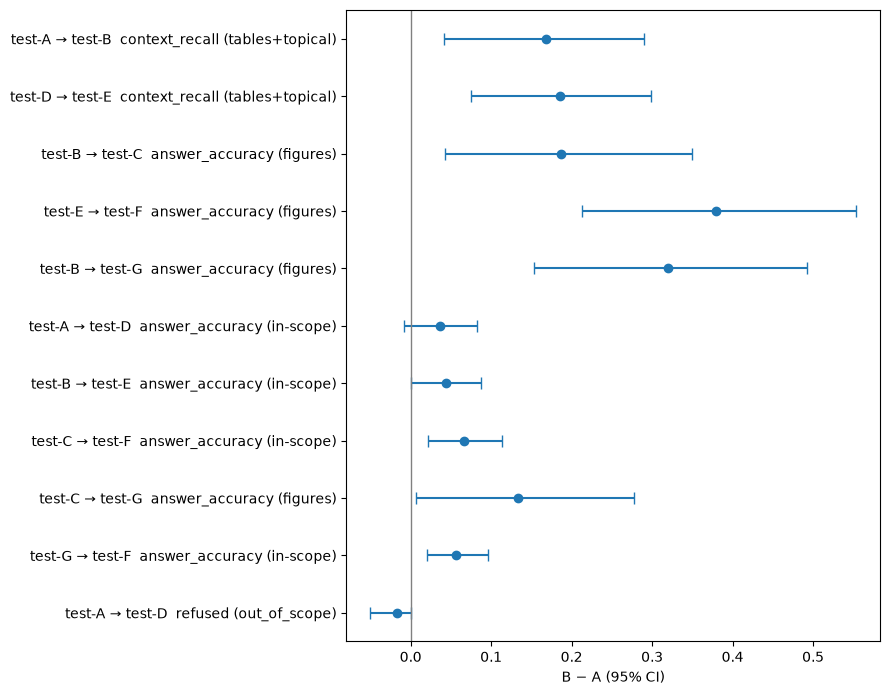

In [5]:
import matplotlib.pyplot as plt

shown = comparisons.dropna(subset=["diff"])
labels = [f"{r.A} → {r.B}  {r.metric} ({r.groups})" for r in shown.itertuples()]
fig, ax = plt.subplots(figsize=(9, 0.55 * len(shown) + 1))
ax.errorbar(shown["diff"], range(len(shown)), xerr=[shown["diff"] - shown["ci_low"], shown["ci_high"] - shown["diff"]], fmt="o", capsize=4)
ax.axvline(0, color="grey", linewidth=1)
ax.set_yticks(range(len(shown)), labels)
ax.invert_yaxis()
ax.set_xlabel("B − A (95% CI)")
plt.tight_layout()

## Answering cost and time per question

OpenAI models are priced per token; Qwen per second of model working time (llama-server's prompt + generation time) at `E.GPU_PRICE_PER_HOUR`. RunPod queueing, cold starts and job overhead are shown (`runpod_exec_s`, `runpod_delay_s`) but not charged. `wall_s` is the question's end-to-end time as the evaluation saw it.

In [6]:
E.answering_cost(DONE)

,answers,calls/q,prompt_tokens/q,completion_tokens/q,model_s/q,runpod_exec_s/q,runpod_delay_s/q,wall_s/q (median),"cost per 1,000 questions ($)"
run,,,,,,,,,
test-A,510,3.0,2296,156,None,None,None,4.2,0.44
test-B,510,3.0,2392,173,None,None,None,4.6,0.46
test-C,510,3.0,2435,174,None,None,None,4.7,0.47
test-D,510,3.0,2293,407,None,None,None,7.4,0.95
test-E,510,3.0,2354,401,None,None,None,7.4,0.95
test-F,510,3.0,2428,411,None,None,None,7.4,0.98
test-G,510,3.0,2457,177,None,None,None,4.6,0.47


## Judge agreement (Haiku 5.5 vs Sonnet 5.5 on context recall)

In [7]:
E.judge_agreement(DONE)

{'metric': 'context_recall',
 'n': 300,
 'haiku_mean': 0.874,
 'sonnet_mean': 0.881,
 'mean_abs_diff': 0.018,
 'identical_share': 0.97,
 'correlation': 0.933}

## Judge spend (Anthropic)

In [8]:
spend = E.judge_spend(DONE)
display(spend.groupby(["run", "model"])[["calls", "input_tokens", "output_tokens", "cost_usd"]].sum())
print(f"total ${spend.cost_usd.sum():.2f}")

calls  input_tokens  output_tokens  cost_usd
run    model                                                          
test-A claude-haiku-5-5    2760       5523149         687024    0.8959
       claude-sonnet-5-5    900       1137996           9000    2.3659
test-B claude-haiku-5-5    2760       5742750         764743    0.9566
       claude-sonnet-5-5    900       1169261           9000    2.4285
test-C claude-haiku-5-5    2760       5804502         752395    0.9566
       claude-sonnet-5-5   1050       1848082          41789    4.1141
test-D claude-haiku-5-5    2760       5597539         712804    0.9162
       claude-sonnet-5-5    900       1161553           9000    2.4131
test-E claude-haiku-5-5    2760       5682119         708585    0.9225
       claude-sonnet-5-5    900       1167627           9000    2.4253
test-F claude-haiku-5-5    2762       5870164         776008    0.9751
       claude-sonnet-5-5   1050       1865189          41712    4.1475
test-G claude-haiku-5-5    2762       5892819         787069    0.9829
       claude-sonnet-5-5    900       1175481           9000    2.4409

total $26.94
